# 04 · Classifier

**Goal:** replace the hand-set rules from notebook 03 with models that learn from the data, then compare them with the rules and the CMID-only baseline on the same scorecard.

The classifier works in two steps, the standard setup for record matching:
1. **Score every pair.** For each (entry, candidate matter) row in the pairs table, a model gives the probability that it's the right matter.
2. **Decide the action.** A second model looks at the whole entry (how the top candidates score, how many parts the narrative has, whether the typed client is known, and whether the wording mentions other work) and gives the probability that the top pick is safe to accept, that the entry covers more than one matter, or that it's a new client or matter. Cutoffs tuned on TRAIN turn those into one of the five decisions.

Each decision also gets a short and a full reason in plain language, built from that entry's own clues.

**What counts as good:** a high share of the decisions made with no person (`AUTO_MATCH` and `NO_MATCH`) are right, and as many entries as possible are decided that way (the **straight-through rate**). Three settings are kept: strict (at least 98% right), default (at least 97% right, the chosen setting), and balanced (the rules' accuracy).

**Questions**
1. Which model ranks the right matter first most often: logistic regression or gradient boosting?
2. Can its probabilities be trusted as confidence scores?
3. How far does a one-step version (cutoffs on the top probabilities) get, and what holds it back?
4. Does the second step reach the 98% and 97% targets, and at what straight-through rate?
5. Which clues matter most?
6. Do the results hold on VAL?
7. What does a reviewer see for each decision?

## 1. Setup

In [1]:
import itertools
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score, log_loss
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "../src")
from rules import (ACTIONS, OUTCOMES, answer_key, pick_best, precision_ci, run_rules, score, cmid_only, summarize,
                   cutoff_stability)
from classifier import (top_candidates, route, top_k_accuracy, entry_features, action_labels, route_actions,
                        multi_text_model, explain, ACTION_FEATURES)

In [2]:
RESULTS_DIR = Path("../results")
SEED = 210

LR_GRID = {"logisticregression__C": [0.01, 0.1, 1, 10]}
GB_GRID = {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31], "min_samples_leaf": [20, 100, 200]}
ROUTE_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995, 0.999],
    "multi_min": [0.5, 0.7, 0.9],
    "no_match_max": [0.02, 0.05, 0.1, 0.2],
}
ACTION_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995],
    "no_match_min": [0.3, 0.5, 0.7, 0.9, 0.95],
}
MULTI_GRID = np.round(np.arange(0.05, 0.95, 0.05), 2)
MULTI_BETA = 2   # a missed multi-matter entry counts about twice as much as a false alarm (section 7)
ACTION_GB_GRID = {"max_iter": [50, 100, 200], "min_samples_leaf": [50, 100, 200]}
TEXT_GRID = {"logisticregression__C": [0.3, 1, 3, 10]}
DEFAULT_TARGET = 0.97   # the chosen setting: at least 97% of automatic decisions right (section 7)
CORRECT_TYPED_CMID = True   # auto-match to the top pick when it's confident a typed CMID is wrong (False = flag it)
STABILITY_RESAMPLES = 200   # TRAIN resamples for the cutoff stability check (section 7)

## 2. Load data

Same pairs table as notebook 03: 103 rows per entry, one per candidate matter. `is_true_matter` is the label (1 for the right matter, and for both matters of a multi-matter entry), and `fold` assigns each TRAIN entry to one of notebook 02's 5 cross-validation folds. The clue columns come from notebook 02's config, and the answer key (`key_` columns) is only used for labels and scoring. The parts table (one row per piece of work) is only used to suggest how to divide multi-matter entries.

In [3]:
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
rules_config = json.loads((RESULTS_DIR / "03_config.json").read_text())
baseline = pd.read_csv(RESULTS_DIR / "03_comparison.csv")
answers = answer_key(pairs)
parts = pd.read_parquet(RESULTS_DIR / "02_parts.parquet")
narratives = pairs.drop_duplicates("entry_id").set_index("entry_id")["narrative_norm"]

feature_groups = feature_config["features"]
FEATURES = [col for cols in feature_groups.values() for col in cols]
CLIENT_COL, MATTER_COL = feature_config["client_col"], feature_config["matter_col"]
PRECISION_TARGET = rules_config["precision_target"]

train_pairs = pairs[pairs["split"] == "TRAIN"].reset_index(drop=True)
val_pairs = pairs[pairs["split"] == "VAL"].reset_index(drop=True)
X_train, y_train = train_pairs[FEATURES], train_pairs["is_true_matter"]
cv = PredefinedSplit(train_pairs["fold"])

assert (pairs.groupby("entry_id").size() == pairs["cmid"].nunique()).all()
assert pairs[FEATURES].notna().all().all()
assert train_pairs.groupby("entry_id")["fold"].nunique().eq(1).all()
print(f"{len(FEATURES)} features | TRAIN: {train_pairs['entry_id'].nunique():,} entries ({len(train_pairs):,} pairs) | "
      f"VAL: {val_pairs['entry_id'].nunique():,} entries | right matter in {y_train.mean():.1%} of TRAIN pairs")

46 features | TRAIN: 2,802 entries (288,606 pairs) | VAL: 601 entries | right matter in 1.0% of TRAIN pairs


- About 1 in 100 pairs is the right matter, so **row accuracy is useless here**: a model that always says "no" would be 99% accurate. Everything below is measured per entry instead.

## 3. How the classifier decides

**Step 1: score every pair.** Two models are compared:
- **Logistic regression:** one weight per clue, easy to read, a good sanity check.
- **Gradient boosting** (`HistGradientBoostingClassifier`): many small decision trees, each fixing the last one's mistakes. It can pick up combinations ("typed client matches *and* the timekeeper billed it") that one weight per clue can't. It's the usual choice for tables of features like this one.

**Keeping entries together.** All 103 rows of an entry have to land in the same fold, or the model would see part of an entry while training and get graded on the rest of it. Notebook 02 assigned each TRAIN entry to a fold and built the past-narrative clue with those same folds, so `PredefinedSplit` cross-validates on exactly those folds.

**Step 2: decide the action.** First a one-step version for comparison (`route` in `src/classifier.py`): cutoffs on the top two probabilities, tried in this order.

| # | if... | then |
|---|---|---|
| 1 | no candidate scores above `no_match_max` | `NO_MATCH` |
| 2 | the second-best candidate scores at least `multi_min` | `MULTI_MATTER` with both matters |
| 3 | a valid typed CMID isn't the top pick, or the typed matter wasn't open | `FLAG_MISMATCH`, suggesting the top pick |
| 4 | the top pick scores at least `auto_min` but wasn't open on the work date | `FLAG_MISMATCH` |
| 5 | the top pick scores at least `auto_min` | `AUTO_MATCH` |
| 6 | otherwise | `NEEDS_REVIEW` with the top 3 as a shortlist |

Then the **action model** (section 7), which replaces the cutoffs on raw probabilities with learned probabilities for each action.

**Scoring** is the same as notebook 03 (`score` and `summarize` in `src/rules.py`). Cutoffs are picked with the same rule: among settings with `decided_precision` at or above the target (98% for strict, 97% for default), the highest `straight_through`; if none reach it, the highest precision to the half point.

## 4. Step 1: tune and compare the two models (TRAIN)

Each grid is searched over the 5 folds from notebook 02, scored by **log loss** (how far the probabilities are from the true 0/1 labels, lower is better). Gradient boosting stops adding trees once a held-out slice of the training fold stops improving (`early_stopping`). The gradient boosting grid takes a few minutes.

In [4]:
searches = {
    "logistic regression": GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                                        LR_GRID, cv=cv, scoring="neg_log_loss"),
    "gradient boosting": GridSearchCV(HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=SEED),
                                      GB_GRID, cv=cv, scoring="neg_log_loss"),
}
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name}: {search.best_params_} | log loss {-search.best_score_:.4f}")

logistic regression: {'logisticregression__C': 10} | log loss 0.0135
gradient boosting: {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 100} | log loss 0.0092


In [5]:
gb_grid = pd.DataFrame(searches["gradient boosting"].cv_results_)
gb_grid["log_loss"] = -gb_grid["mean_test_score"]
gb_grid[["param_learning_rate", "param_max_leaf_nodes", "param_min_samples_leaf", "log_loss", "mean_fit_time"]].sort_values("log_loss").round(4)

,param_learning_rate,param_max_leaf_nodes,param_min_samples_leaf,log_loss,mean_fit_time
4,0.05,31,100,0.0092,8.4420
5,0.05,31,200,0.0093,7.6767
1,0.05,15,100,0.0096,6.5353
2,0.05,15,200,0.0096,5.7221
3,0.05,31,20,0.0099,6.2661
11,0.10,31,200,0.0101,4.3043
10,0.10,31,100,0.0102,3.6001
8,0.10,15,200,0.0103,2.7034
7,0.10,15,100,0.0104,2.8110
0,0.05,15,20,0.0104,4.1100


- A smaller learning rate (0.05) with larger leaves (`min_samples_leaf` 100 or 200) works best. Leaves that need more rows keep the trees from memorizing single entries.
- The settings with `min_samples_leaf` 20 and learning rate 0.1 do worst, with up to about twice the log loss of the best.

### Cross-validated probabilities

Each model with its best settings is refit fold by fold, so every TRAIN entry gets probabilities from a model that never saw it. Everything tuned in sections 6 and 7 uses these. **Top-1** is the share of entries whose right matter is ranked first, and **top-3** is the share where it's in the top three (what a reviewer's shortlist would show).

In [6]:
cv_probs = {name: cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
            for name, search in searches.items()}

model_scores = pd.DataFrame({name: {"log_loss": log_loss(y_train, p),
                                    "top_1": top_k_accuracy(train_pairs, p, k=1),
                                    "top_3": top_k_accuracy(train_pairs, p, k=3)}
                             for name, p in cv_probs.items()}).T
chosen_model = model_scores["top_1"].idxmax()
best_model = searches[chosen_model].best_estimator_
print("Chosen model:", chosen_model)
model_scores.round(3)

Chosen model: gradient boosting


,log_loss,top_1,top_3
logistic regression,0.014,0.855,0.953
gradient boosting,0.009,0.920,0.973


- **Gradient boosting ranks the right matter first for 92% of entries**, vs. 86% for logistic regression, and has it in the top 3 for 97%.
- Its log loss is also about a third lower, so the gain isn't just in the ranking: the probabilities themselves are closer to the truth.

## 5. Can the probabilities be trusted?

Cutoffs only make sense if a 0.9 really means "right about 9 times in 10". A **calibration plot** checks this: candidates are grouped by predicted probability, and each group's predicted average is plotted against how often it was actually the right matter. A calibrated model sits on the diagonal.

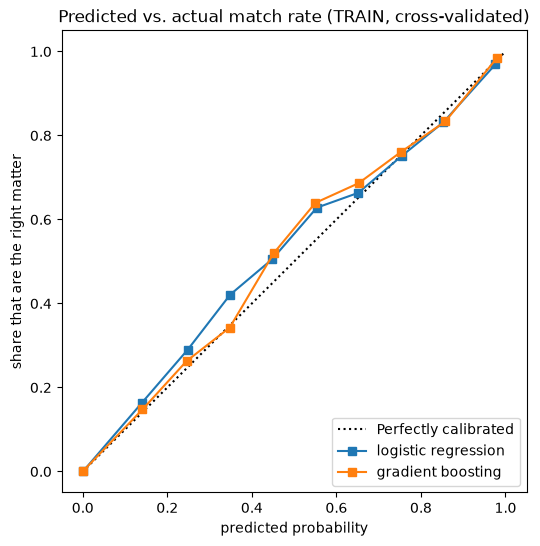

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in cv_probs.items():
    CalibrationDisplay.from_predictions(y_train, p, n_bins=10, name=name, ax=ax)
ax.set(title="Predicted vs. actual match rate (TRAIN, cross-validated)", xlabel="predicted probability", ylabel="share that are the right matter")
plt.show()

- Both models stay close to the diagonal. Gradient boosting is a little under-confident between 0.4 and 0.7 (right somewhat more often than it says), which is the safe direction, so its probabilities can be used as confidence scores without an extra calibration step.
- Notebook 05 checks calibration again on each entry's top pick, the probability a reviewer actually sees.

## 6. One step: cutoffs on the top probabilities (TRAIN)

Every combination of the three cutoffs is tried on the cross-validated probabilities (108 combinations).

In [8]:
ranked_train = top_candidates(train_pairs, cv_probs[chosen_model])

one_sweep = {}
for settings in itertools.product(*ROUTE_GRID.values()):
    one_sweep[settings] = summarize(score(route(ranked_train, dict(zip(ROUTE_GRID, settings))), answers))
one_sweep = pd.DataFrame(one_sweep).T.rename_axis(list(ROUTE_GRID))

one_step = {k: float(v) for k, v in zip(ROUTE_GRID, pick_best(one_sweep, PRECISION_TARGET))}
scored_one = score(route(ranked_train, one_step), answers)
wrong_one = scored_one[scored_one["outcome"] == "Accepted, wrong"]
print("Cutoffs:", one_step)
print({k: round(v, 3) for k, v in summarize(scored_one).items() if k in ["decided_precision", "straight_through", "review_share"]})
wrong_one["key_entry_category"].value_counts().rename("wrong auto-accepts").to_frame()

Cutoffs: {'auto_min': 0.98, 'multi_min': 0.5, 'no_match_max': 0.02}
{'straight_through': 0.465, 'decided_precision': 0.936, 'review_share': 0.421}


,wrong auto-accepts
key_entry_category,
MULTI_UNNAMED,45
MULTI_NAMED,26
WRONG_CMID_TEXT,2
NO_MATCH,1
MESSY,1


- **One step tops out around 94%.** Nothing reaches 98%, so the rule falls back to the most precise setting (to the half point), with `auto_min` 0.98, which decides about 47% of entries with no person.
- **Almost every leftover error is a multi-matter entry** (71 of 75): the right matter is accepted, but the entry covered two matters. A cutoff on one candidate's probability can't see that, so it's what step 2 is for.

## 7. Step 2: an action model

Each TRAIN entry gets one row of entry-level clues (`entry_features` in `src/classifier.py`): the top three probabilities and their total, whether the top two are the same client, how the typed CMID compares, the top picks' past-narrative scores, the best typed-name scores, and narrative counts (parts, task types, matters and clients named). The label is what should happen to the entry (`action_labels`):

| label | when |
|---|---|
| `multi` | the entry covers more than one matter |
| `no_match` | the client or matter isn't in Matter Master |
| `auto` | otherwise, and the top pick is the right matter |
| `review` | otherwise (the top pick is wrong) |

A second gradient boosting model learns these labels from the cross-validated step-1 probabilities, using the same folds, so step 2 never sees probabilities from a model that saw the entry. Its number of trees and leaf size are tuned on those folds by log loss, like step 1. Early stopping is off here: it holds out a random slice of entries, and with only about 2,800 TRAIN entries the result depends too much on which ones land in that slice.

**Narrative score.** Multi-matter entries are hard to spot from scores alone: block-billed entries also have several parts, and many multi-matter narratives never name the second matter ("misc. calls for other client"). So the action model also gets a score from a small text model (`multi_text_model`: TF-IDF on words and word pairs, then logistic regression). It reads only the narrative and learns wording that signals other work. Its strength (`C`) is tuned on the same folds, and TRAIN entries get out-of-fold scores, so the action model never sees a score from a model trained on that entry.

In [9]:
entries_train = entry_features(train_pairs, cv_probs[chosen_model], CLIENT_COL, MATTER_COL)
labels = action_labels(entries_train, answers)
entry_folds = entries_train["entry_id"].map(train_pairs.drop_duplicates("entry_id").set_index("entry_id")["fold"])
entry_cv = PredefinedSplit(entry_folds)

narrative_train = entries_train["entry_id"].map(narratives)
is_multi = labels == "multi"
text_search = GridSearchCV(multi_text_model(), TEXT_GRID, cv=entry_cv, scoring="neg_log_loss").fit(narrative_train, is_multi)
text_model = text_search.best_estimator_
entries_train["multi_text_score"] = cross_val_predict(text_model, narrative_train, is_multi, cv=entry_cv, method="predict_proba")[:, 1]

action_search = GridSearchCV(HistGradientBoostingClassifier(learning_rate=0.05, early_stopping=False, random_state=SEED),
                             ACTION_GB_GRID, cv=entry_cv, scoring="neg_log_loss")
action_search.fit(entries_train[ACTION_FEATURES], labels)
action_model = action_search.best_estimator_
action_cv = pd.DataFrame(cross_val_predict(action_model, entries_train[ACTION_FEATURES], labels, cv=entry_cv, method="predict_proba"),
                         columns=action_model.classes_)
print(f"text model: {text_search.best_params_} | action model: {action_search.best_params_} | log loss {-action_search.best_score_:.3f}")
pd.Series(labels).value_counts().rename("TRAIN entries").to_frame()

text model: {'logisticregression__C': 10} | action model: {'max_iter': 50, 'min_samples_leaf': 50} | log loss 0.316


,TRAIN entries
auto,2254
review,200
no_match,174
multi,174


In [10]:
words = pd.Series(text_model[-1].coef_[0], index=text_model[0].get_feature_names_out())
words.nlargest(12).round(2).rename("weight toward multi-matter").to_frame()

,weight toward multi-matter
other,11.28
for,8.57
separate,5.27
to separate,5.27
on other,5.11
transaction,4.85
re unrelated,4.80
unrelated,4.80
for other,4.71
different,4.58


- **The words that push hardest toward multi-matter are about other work:** "other", "separate", "unrelated", "different", "for other". None of them name a matter, which is why scores alone miss these entries.
- The tuning picks the largest `C` (10), so the model leans on these words heavily. That works here because the synthetic data reuses the same phrases. Real narratives will be more varied, so the text model would need retraining on real entries.

### Tune the action cutoffs (TRAIN)

`route_actions` uses the same order as the one-step version, but on the action model's probabilities: `NO_MATCH` if P(no_match) is at least `no_match_min`, `MULTI_MATTER` if P(multi) is at least `multi_min`, then flags, then `AUTO_MATCH` if P(auto) is at least `auto_min`, otherwise review.

**Typed CMIDs the model disagrees with.** With `CORRECT_TYPED_CMID` on, an entry whose typed CMID isn't the top pick is auto-matched to the top pick when P(auto) clears `auto_min` and that matter was open, and its reason says the typed CMID was corrected. Below the cutoff it's still flagged. With it off, every disagreement is flagged for a person to accept the suggestion. It's one setting, so a firm that never wants a typed CMID changed can turn it off, and the cutoffs below are tuned with whichever choice is set.

**`multi_min` is learned first, on its own,** as the cutoff on P(multi) with the best **F2 score** on the cross-validated predictions. The two possible mistakes don't cost the same:
- A **missed** multi-matter entry goes to regular review, where someone could confirm one matter and miss the second, so part of the time is billed wrong or lost.
- A **false alarm** costs a reviewer a few seconds.

F2 counts a miss about twice as much as a false alarm (`MULTI_BETA`). A firm that weighs them differently can change that one setting and the cutoff is relearned.

**Then `auto_min` and `no_match_min`** are tuned with `multi_min` fixed (55 combinations), and three sets are kept:
- **Strict:** the 98% target, with the highest straight-through rate.
- **Default (the chosen setting):** a 97% target, with the highest straight-through rate. Giving up one point of precision lets the classifier decide noticeably more entries on its own, which fits the goal of less review while wrong matches stay rare.
- **Balanced:** the highest straight-through rate that still matches the rules' decided precision on TRAIN, to show how much more the classifier can automate at the rules' accuracy.

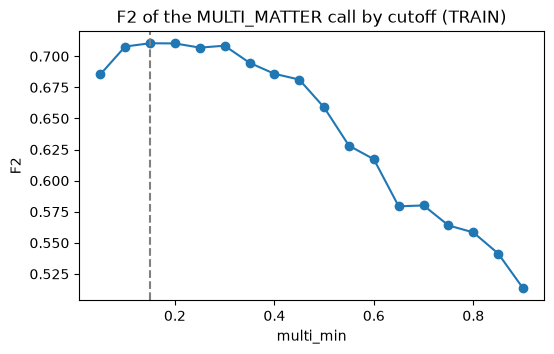

multi_min = 0.15


In [11]:
multi_score = pd.Series({t: fbeta_score(is_multi, action_cv["multi"] >= t, beta=MULTI_BETA) for t in MULTI_GRID})
multi_min = float(multi_score.idxmax())
ax = multi_score.plot(marker="o", figsize=(6, 3.5), title=f"F{MULTI_BETA} of the MULTI_MATTER call by cutoff (TRAIN)")
ax.axvline(multi_min, color="gray", linestyle="--")
ax.set(xlabel="multi_min", ylabel=f"F{MULTI_BETA}")
plt.show()
print(f"multi_min = {multi_min}")

In [12]:
same_for_all = {"multi_min": multi_min, "correct_typed_cmid": CORRECT_TYPED_CMID}
two_sweep, two_scored = {}, {}
for settings in itertools.product(*ACTION_GRID.values()):
    cfg = dict(zip(ACTION_GRID, settings)) | same_for_all
    two_scored[settings] = score(route_actions(entries_train, action_cv, cfg), answers)
    two_sweep[settings] = summarize(two_scored[settings])
two_sweep = pd.DataFrame(two_sweep).T.rename_axis(list(ACTION_GRID))

rules_precision = baseline.query("method == 'rules' and split == 'TRAIN' and entry_set == 'all'")["decided_precision"].iloc[0]
strict = {k: float(v) for k, v in zip(ACTION_GRID, pick_best(two_sweep, PRECISION_TARGET))} | same_for_all
default = {k: float(v) for k, v in zip(ACTION_GRID, pick_best(two_sweep, DEFAULT_TARGET))} | same_for_all
balanced = {k: float(v) for k, v in zip(ACTION_GRID, pick_best(two_sweep, rules_precision))} | same_for_all
print("Strict:", strict, "| Default:", default, "| Balanced:", balanced)

pd.DataFrame({"one step": one_sweep.loc[tuple(one_step.values())],
              "two steps, strict": two_sweep.loc[(strict["auto_min"], strict["no_match_min"])],
              "two steps, default": two_sweep.loc[(default["auto_min"], default["no_match_min"])],
              "two steps, balanced": two_sweep.loc[(balanced["auto_min"], balanced["no_match_min"])]}).T[
    ["decided_precision", "straight_through", "review_share", "multi_share", "multi_flag_right", "multi_caught", "no_match_precision"]].round(3)

Strict: {'auto_min': 0.97, 'no_match_min': 0.7, 'multi_min': 0.15, 'correct_typed_cmid': True} | Default: {'auto_min': 0.93, 'no_match_min': 0.9, 'multi_min': 0.15, 'correct_typed_cmid': True} | Balanced: {'auto_min': 0.5, 'no_match_min': 0.3, 'multi_min': 0.15, 'correct_typed_cmid': True}


,decided_precision,straight_through,review_share,multi_share,multi_flag_right,multi_caught,no_match_precision
one step,0.936,0.465,0.421,0.028,0.218,0.098,0.879
"two steps, strict",0.981,0.550,0.302,0.086,0.554,0.764,0.936
"two steps, default",0.971,0.635,0.227,0.086,0.554,0.764,0.972
"two steps, balanced",0.911,0.875,0.026,0.086,0.554,0.764,0.785


- **`multi_min` lands at 0.15.** Weighting misses more than false alarms pushes the cutoff low: on TRAIN, 76% of multi-matter entries get the call, and 55% of calls are right. Precision and the straight-through rate don't depend on this cutoff, since every `MULTI_MATTER` call goes to a person anyway.
- **Strict** reaches 98.1% decided precision with 55% of entries decided with no person.
- **Default** gives up about one point (97.1%) to decide 64% with no person and send 23% to review instead of 30%.
- **Balanced** gives up more (91.1%) to decide 88% with no person and send only 3% to review.
- **Strict and default land on different new-client cutoffs** (`no_match_min` 0.7 and 0.9). Default's higher cutoff calls fewer entries new clients, but more of those calls are right (97% vs. 94%).

### How stable are the cutoffs?

Strict and default each sit near their target on TRAIN, so a slightly different TRAIN set could pick different cutoffs. To check, TRAIN is resampled by timekeeper (`STABILITY_RESAMPLES` times, whole timekeepers drawn with replacement, since one person's entries are alike) and the best setting is picked again each time with the same rule (`cutoff_stability` in `src/rules.py`). The table shows how often each setting wins. Nothing is refit, so this measures how much the choice depends on which entries are in TRAIN.

In [13]:
stability = pd.DataFrame({name: cutoff_stability(two_scored, target, STABILITY_RESAMPLES, SEED)
                          for name, target in [("strict", PRECISION_TARGET), ("default", DEFAULT_TARGET)]}).fillna(0)
stability.index = [f"auto_min {a}, no_match_min {n}" for a, n in stability.index]
stability.sort_values("default", ascending=False).round(2)

,strict,default
"auto_min 0.95, no_match_min 0.7",0.11,0.16
"auto_min 0.93, no_match_min 0.9",0.04,0.14
"auto_min 0.9, no_match_min 0.5",0.00,0.14
"auto_min 0.95, no_match_min 0.5",0.08,0.13
"auto_min 0.9, no_match_min 0.9",0.00,0.12
"auto_min 0.9, no_match_min 0.7",0.00,0.10
"auto_min 0.93, no_match_min 0.7",0.00,0.08
"auto_min 0.95, no_match_min 0.9",0.22,0.08
"auto_min 0.93, no_match_min 0.5",0.02,0.01
"auto_min 0.9, no_match_min 0.95",0.00,0.01


- **The exact cutoffs aren't stable.** The most common default setting wins only about 1 in 6 resamples, and strict's choices are just as spread out.
- **The range is stable:** default's `auto_min` lands between 0.9 and 0.95 in almost every resample, and strict's between 0.95 and 0.99 in about 9 in 10. The settings in that range perform about the same on TRAIN, so which one wins depends on a handful of entries.
- **`no_match_min` moves the most** (0.5 to 0.9), so how many entries are called new clients is the least settled part of the setup.
- In practice, the target (97% or 98%) is the decision that matters. The exact cutoff it lands on is a detail that should be re-picked whenever the model is refit.

### Precision vs. straight-through rate

Each line moves `auto_min` with the other cutoffs at their strict values. Up and to the right is better: more entries decided with no person, at higher precision.

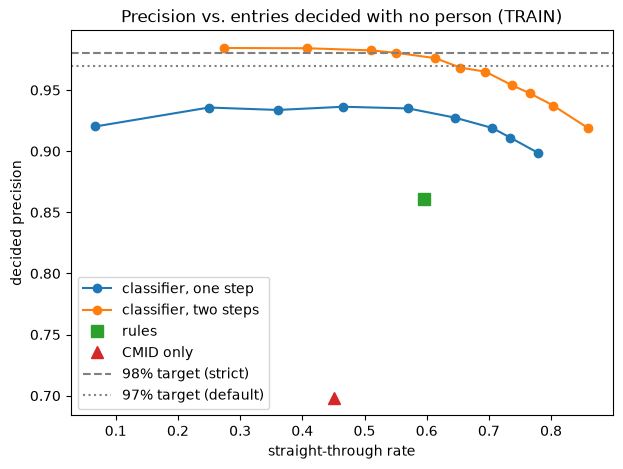

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, sweep, cfg, fixed in [("one step", one_sweep, one_step, ["multi_min", "no_match_max"]),
                                ("two steps", two_sweep, strict, ["no_match_min"])]:
    curve = sweep.xs(tuple(cfg[k] for k in fixed), level=fixed)
    ax.plot(curve["straight_through"], curve["decided_precision"], marker="o", label=f"classifier, {name}")
for method, marker in [("rules", "s"), ("CMID only", "^")]:
    row = baseline.query("method == @method and split == 'TRAIN' and entry_set == 'all'").iloc[0]
    ax.plot(row["straight_through"], row["decided_precision"], marker=marker, markersize=9, linestyle="", label=method)
ax.axhline(PRECISION_TARGET, color="gray", linestyle="--", label="98% target (strict)")
ax.axhline(DEFAULT_TARGET, color="gray", linestyle=":", label="97% target (default)")
ax.set(title="Precision vs. entries decided with no person (TRAIN)", xlabel="straight-through rate", ylabel="decided precision")
ax.legend()
plt.show()

- **The two-step line sits above the one-step line everywhere** and crosses the 98% target, which one step never reaches.
- At the strict cutoffs, step 2 decides 55% of entries with no person (vs. 47% for one step) at much higher precision (98.1% vs. 93.6%).
- At the default cutoffs (`auto_min` 0.93), it decides 64% with no person at 97.1%: about 9 points more automation than strict for about 1 point of precision.
- The rules sit well below both classifier lines.

## 8. The default classifier on TRAIN

Rows are what the answer key expects and columns are what the classifier decided.

In [15]:
scored_train = score(route_actions(entries_train, action_cv, default), answers)
pd.crosstab(scored_train["key_expected_action"], scored_train["action"]).reindex(index=ACTIONS, columns=ACTIONS, fill_value=0)

action,AUTO_MATCH,FLAG_MISMATCH,NEEDS_REVIEW,MULTI_MATTER,NO_MATCH
key_expected_action,,,,,
AUTO_MATCH,1533,83,413,90,1
FLAG_MISMATCH,68,64,24,12,0
NEEDS_REVIEW,83,0,80,2,1
MULTI_MATTER,21,1,19,133,0
NO_MATCH,3,0,99,3,69


In [16]:
wrong = scored_train[scored_train["outcome"] == "Accepted, wrong"]
wrong["key_entry_category"].value_counts().rename("wrong auto-accepts").to_frame()

,wrong auto-accepts
key_entry_category,
MULTI_NAMED,21
WRONG_CMID_TEXT,8
AMBIGUOUS,6
INCOMPLETE,5
NO_MATCH,3
WRONG_CMID_SILENT,3
CLEAN,2
MESSY,2


- **Most multi-matter entries are caught:** 133 of 174 get the call. Of the rest, 21 are auto-matched to one matter, 19 go to review, and 1 is flagged.
- **The price is false alarms:** 107 one-matter entries also get the call (mostly block-billed ones). Each costs a reviewer a few seconds to clear.
- **Wrong auto-accepts stay low:** 50 out of about 1,700 auto-accepts, vs. 22 for strict and 75 for one step. Twenty-one are named multi-matter entries, and the rest are spread across wrong CMIDs, vague entries, and new clients.
- **Typed CMIDs are corrected when the model is confident:** 99 TRAIN entries are auto-matched to a different matter than the typed CMID, and 96 of them are right. These are most of the expected `FLAG_MISMATCH` entries that now get `AUTO_MATCH`.
- **Review is the biggest bucket** (23% of TRAIN, down from 30% under strict), and about 2 in 3 reviewed entries should have been auto-matched, so most reviews are a quick confirmation.
- **New clients mostly go to review** (99 of 174) at this setting, because of the higher `no_match_min`. That's safe, but it's more review.

## 9. Which clues matter? (step 1)

Each group of clues from notebook 02 is dropped in turn, the step-1 model is retrained with the same settings, and the change in cross-validated top-1 accuracy is recorded. A big drop means the model leans on that group. This retrains the model 40 times, so it takes a few minutes.

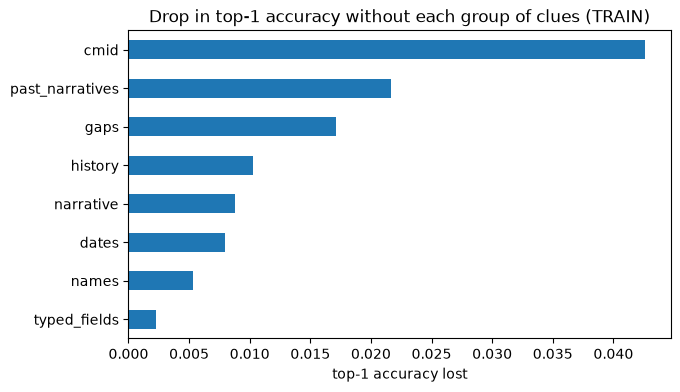

In [17]:
full_top_1 = model_scores.loc[chosen_model, "top_1"]

drop = {}
for group, cols in feature_groups.items():
    kept = [c for c in FEATURES if c not in cols]
    p = cross_val_predict(clone(best_model), X_train[kept], y_train, cv=cv, method="predict_proba")[:, 1]
    drop[group] = full_top_1 - top_k_accuracy(train_pairs, p, k=1)

ax = pd.Series(drop).sort_values().plot.barh(figsize=(7, 4), title="Drop in top-1 accuracy without each group of clues (TRAIN)")
ax.set_xlabel("top-1 accuracy lost")
plt.show()

- **The CMID clues matter most**, then **past narratives** and the gaps to the best candidate (about 2 points of top-1 each), then timekeeper history, the other narrative clues, and dates (about 1 point each), then typed names (about half a point).
- Past narratives, built from billing history instead of a curated key-term list, are the second most useful group of clues.
- Dropping the typed-field flags barely changes anything, likely because the gap columns and CMID clues already carry the same information.

## 10. Check on VAL (once)

Both models were refit on all of TRAIN. VAL goes through both steps with the cutoffs from sections 6 and 7, and nothing changes after this. The interval is a 95% bootstrap range for decided precision: with about 600 entries, differences of 2 to 3 points can be noise.

In [18]:
val_probs = best_model.predict_proba(val_pairs[FEATURES])[:, 1]
entries_val = entry_features(val_pairs, val_probs, CLIENT_COL, MATTER_COL)
entries_val["multi_text_score"] = text_model.predict_proba(entries_val["entry_id"].map(narratives))[:, 1]
action_val = pd.DataFrame(action_model.predict_proba(entries_val[ACTION_FEATURES]), columns=action_model.classes_)

runs = {("classifier, one step", "TRAIN"): scored_one,
        ("classifier, one step", "VAL"): score(route(top_candidates(val_pairs, val_probs), one_step), answers),
        ("classifier (strict)", "TRAIN"): score(route_actions(entries_train, action_cv, strict), answers),
        ("classifier (strict)", "VAL"): score(route_actions(entries_val, action_val, strict), answers),
        ("classifier (default)", "TRAIN"): scored_train,
        ("classifier (default)", "VAL"): score(route_actions(entries_val, action_val, default), answers),
        ("classifier (balanced)", "TRAIN"): score(route_actions(entries_train, action_cv, balanced), answers),
        ("classifier (balanced)", "VAL"): score(route_actions(entries_val, action_val, balanced), answers)}

rows = {}
for (method, split), scored in runs.items():
    rows[(method, split, "all")] = summarize(scored)
    rows[(method, split, "non-trivial")] = summarize(scored[scored["key_trivial"] == "N"])
new_rows = pd.DataFrame(rows).T.rename_axis(["method", "split", "entry_set"]).reset_index()
comparison = pd.concat([baseline[~baseline["method"].str.startswith("classifier")], new_rows], ignore_index=True)

val_runs = {"CMID only": score(run_rules(val_pairs, rules_config["rules"], cmid_only), answers),
            "rules": score(run_rules(val_pairs, rules_config["rules"]), answers)}
val_runs |= {method: scored for (method, split), scored in runs.items() if split == "VAL"}

val_table = pd.DataFrame({name: summarize(scored) for name, scored in val_runs.items()}).T
val_table[["ci_low", "ci_high"]] = [precision_ci(scored) for scored in val_runs.values()]
val_table[["decided_precision", "ci_low", "ci_high", "straight_through", "review_share", "silent_errors", "silent_by_design",
           "multi_share", "multi_flag_right", "multi_caught", "no_match_precision", "shortlist_hit"]].round(3)

,decided_precision,ci_low,ci_high,straight_through,review_share,silent_errors,silent_by_design,multi_share,multi_flag_right,multi_caught,no_match_precision,shortlist_hit
CMID only,0.687,0.632,0.747,0.431,0.569,81.0,32.0,0.000,NaN,0.000,NaN,0.693
rules,0.872,0.831,0.907,0.572,0.324,36.0,17.0,0.022,0.692,0.243,0.771,0.605
"classifier, one step",0.954,0.929,0.977,0.473,0.414,12.0,2.0,0.037,0.136,0.081,0.933,0.880
classifier (strict),0.985,0.974,0.995,0.562,0.293,3.0,3.0,0.083,0.600,0.811,0.926,0.915
classifier (default),0.977,0.961,0.990,0.647,0.221,8.0,4.0,0.083,0.600,0.811,0.938,0.812
classifier (balanced),0.930,0.908,0.950,0.877,0.032,29.0,9.0,0.083,0.600,0.811,0.784,0.789


In [19]:
main = {name: scored for name, scored in val_runs.items() if name != "CMID only"}
accuracy = pd.DataFrame({name: {"matter_accuracy": scored["matter_right"].mean(),
                                "non_trivial": scored.loc[scored["key_trivial"] == "N", "matter_right"].mean(),
                                "action_accuracy": scored["action_right"].mean(),
                                "silent_errors": (scored["outcome"] == "Accepted, wrong").sum()}
                         for name, scored in main.items()}).T
val_table[["decided_precision", "straight_through"]].join(accuracy, how="inner").round(3)

,decided_precision,straight_through,matter_accuracy,non_trivial,action_accuracy,silent_errors
rules,0.872,0.572,0.654,0.561,0.637,36.0
"classifier, one step",0.954,0.473,0.837,0.792,0.534,12.0
classifier (strict),0.985,0.562,0.880,0.841,0.617,3.0
classifier (default),0.977,0.647,0.865,0.821,0.669,8.0
classifier (balanced),0.930,0.877,0.879,0.839,0.795,29.0


In [20]:
from sklearn.metrics import classification_report

for name in ["classifier (strict)", "classifier (default)", "classifier (balanced)"]:
    scored = val_runs[name]
    hard = scored["key_trivial"] == "N"
    print(f"# {name}\n== VAL ==")
    print(f"matter accuracy {scored['matter_right'].mean():.3f} | non-trivial {scored.loc[hard, 'matter_right'].mean():.3f} | "
          f"silent errors {(scored['outcome'] == 'Accepted, wrong').sum()}")
    print(f"action accuracy {scored['action_right'].mean():.3f}")
    print(classification_report(scored["key_expected_action"], scored["action"], digits=3, zero_division=0))

# classifier (strict)
== VAL ==
matter accuracy 0.880 | non-trivial 0.841 | silent errors 3
action accuracy 0.617
               precision    recall  f1-score   support

   AUTO_MATCH      0.904     0.620     0.736       453
FLAG_MISMATCH      0.514     0.528     0.521        36
 MULTI_MATTER      0.600     0.811     0.690        37
 NEEDS_REVIEW      0.091     0.421     0.150        38
     NO_MATCH      0.926     0.676     0.781        37

     accuracy                          0.617       601
    macro avg      0.607     0.611     0.575       601
 weighted avg      0.811     0.617     0.686       601

# classifier (default)
== VAL ==
matter accuracy 0.865 | non-trivial 0.821 | silent errors 8
action accuracy 0.669
               precision    recall  f1-score   support

   AUTO_MATCH      0.887     0.731     0.801       453
FLAG_MISMATCH      0.552     0.444     0.492        36
 MULTI_MATTER      0.600     0.811     0.690        37
 NEEDS_REVIEW      0.075     0.263     0.117        

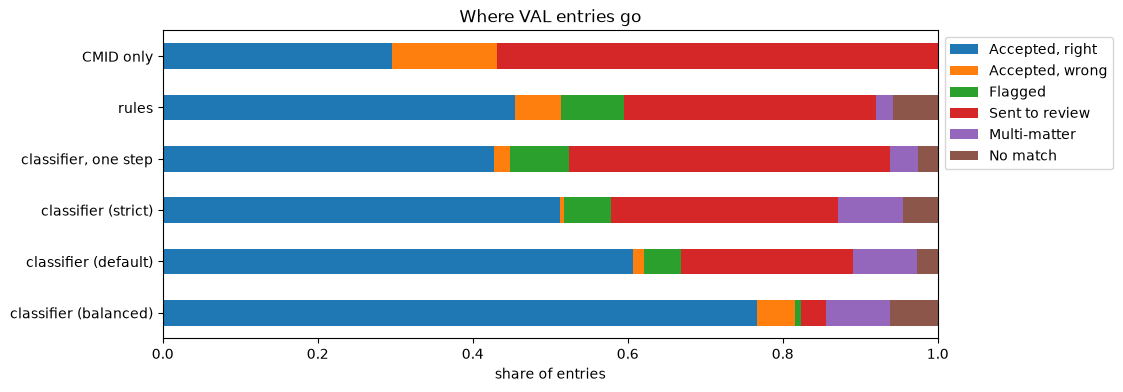

In [21]:
shares = pd.DataFrame({name: scored["outcome"].value_counts(normalize=True) for name, scored in val_runs.items()}).T[OUTCOMES].fillna(0)
ax = shares.plot.barh(stacked=True, figsize=(10, 4), xlim=(0, 1), title="Where VAL entries go")
ax.set_xlabel("share of entries")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

- **Default vs. rules on VAL:** decided precision 97.7% (range 96.1 to 99.0%) vs. 87.2% (83.1 to 90.7%), silent errors drop from 36 to 8, and 65% of entries are decided with no person instead of 57%. The ranges don't overlap, so the gain is real.
- **Default vs. strict:** strict is more precise (98.5%, range 97.4 to 99.5%) with 3 silent errors instead of 8, but decides 56% of entries with no person instead of 65% and sends 29% to review instead of 22%. Strict also catches more new clients (68% vs. 41%), since its new-client cutoff is lower.
- **Strict vs. one step:** more entries decided with no person (56% vs. 47%) at higher precision (98.5% vs. 95.4%), mostly because multi-matter entries are recognized.
- **Balanced vs. rules:** higher precision (93.0% vs. 87.2%), 88% of entries decided with no person instead of 57%, and 3% sent to review instead of 32%, but with 29 silent errors.
- **`MULTI_MATTER`:** 81% of multi-matter entries are caught and 60% of the calls are right (the rules: 24% caught, 69% right). The three settings share the same multi-matter cutoff.
- **Matter and action accuracy:** default picks the right matter for 86.5% of VAL entries (82% of non-trivial ones) and the expected action for 67%, vs. 65% and 64% for the rules. Action accuracy is lower than balanced (80%) because default still sends some entries it has right to review on purpose.
- **Reviewed entries are quick checks:** the true matter is in the top 3 for 81% of reviewed entries under default, vs. 61% for the rules.
- **Typed CMID corrections hold up:** 22 of 24 on VAL are right.
- VAL matches TRAIN closely (default: 97.7% vs. 97.1%, 65% vs. 64% decided with no person), so the models and cutoffs didn't overfit.

## 11. Reasons for each decision

A reviewer needs to know why the tool chose what it chose, but won't read a paragraph for every entry. So each decision gets two reasons, built by `explain` from that entry's own clues:
- **`reason_short`:** a few words for the review list ("Typed CMID matches", "Client clear, matter unclear")
- **`reason_full`:** the decision, a confidence level from the top pick's probability (high 0.9+, medium 0.5+, low), the top pick's strongest clues, and the shortlist. For a multi-matter call, it also suggests which piece of work goes to which matter, from the parts table.

Clues are listed in the order the model leans on them most (section 9), and only clues that are actually present for that entry are shown, so the reason always matches what the model saw.

In [22]:
parts["other_work_score"] = text_model.predict_proba(parts["part_norm"])[:, 1]
inputs = {"TRAIN": (entries_train, train_pairs), "VAL": (entries_val, val_pairs)}
for method, split in runs:
    if method == "classifier, one step":
        continue
    entries, table = inputs[split]
    runs[(method, split)] = explain(runs[(method, split)], entries, table, CLIENT_COL, MATTER_COL, feature_config["phrase_min"], parts)

chosen_val = runs[("classifier (default)", "VAL")]
for _, row in chosen_val.groupby("action").head(2).sort_values("action").iterrows():
    print(f"{row['action']:<14} {row['reason_short']}\n{'':<14} {row['reason_full']}\n")

AUTO_MATCH     Reads like past entries
               Auto-match to 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), high confidence: the narrative reads like past entries on this matter; the timekeeper billed 125.4 hours to it recently; the typed client matches Meridian Therapeutics.

AUTO_MATCH     Typed CMID matches
               Auto-match to 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), high confidence: the typed CMID is this matter; the narrative reads like past entries on this matter; the timekeeper billed 125.4 hours to it recently.

FLAG_MISMATCH  Typed CMID doesn't fit narrative
               Flag: Typed CMID doesn't fit narrative. Suggested 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), low confidence: the timekeeper billed 5.5 hours to it recently; the typed client matches Meridian Therapeutics.

FLAG_MISMATCH  Typed CMID doesn't fit narrative
               Flag: Typed CMID doesn't fit narrative. Suggested 8340.001 (Pelican Row Holdings - Acquis

In [23]:
chosen_val.groupby("action")["reason_short"].value_counts().rename("VAL entries").to_frame()

VAL entries
action        reason_short                                 
AUTO_MATCH    Typed CMID matches                        148
              Reads like past entries                   143
              You've billed this matter                  40
              Typed CMID corrected                       24
              Typed client matches                       14
              Typed matter matches                        2
              Narrative names the matter                  2
FLAG_MISMATCH Typed CMID doesn't fit narrative           29
MULTI_MATTER  May cover two matters                      37
              Mentions other work                        12
              Names two matters                           1
NEEDS_REVIEW  Not sure enough to accept                  61
              No clear match                             35
              Client clear, matter unclear               28
              Close call between matters                  9
NO_MATCH      Likely a new client or matter              16

- **Every decision says why in a few words.** Auto-matches mostly cite the typed CMID (148 of 373) or past entries on the matter (143). When the typed CMID is corrected, the reason says so (24), and flags point out that the typed CMID doesn't fit the narrative.
- **Review reasons tell the reviewer where to look:** the client is clear but the matter isn't, two matters are close, or nothing points anywhere. "Not sure enough to accept" is still the most common (61 of 133): the top pick has some support, and the shortlist and clues in the full reason are the guide.
- **Split suggestions** put the part that seems to be other work on its own, so the timekeeper only has to confirm the second matter and divide the hours. When the call is a false alarm, the suggestion makes that quick to see.

## 12. Save

- `04_decisions.csv`: one row per TRAIN and VAL entry for each classifier version (`method` column), with both reasons, top probabilities, and shortlist. Same columns as `03_decisions.csv` where they overlap, so any later method can be scored the same way.
- `03_comparison.csv`: now also has the classifier's rows
- `04_config.json`: the chosen model, its settings, and all cutoffs
- `04_model.joblib`: the three trained models (pairs, narrative text, action), for the app and later notebooks

In [24]:
decisions = pd.concat([scored.assign(method=method) for (method, split), scored in runs.items()], ignore_index=True)
decisions.to_csv(RESULTS_DIR / "04_decisions.csv", index=False)
comparison.to_csv(RESULTS_DIR / "03_comparison.csv", index=False)
joblib.dump({"pair_model": best_model, "text_model": text_model, "action_model": action_model}, RESULTS_DIR / "04_model.joblib")

config = {"model": chosen_model, "model_params": searches[chosen_model].best_params_, "features": FEATURES,
          "action_features": ACTION_FEATURES, "text_model_params": text_search.best_params_,
          "action_model_params": action_search.best_params_, "routing": {"one_step": one_step, "strict": strict, "default": default, "balanced": balanced},
          "multi_beta": MULTI_BETA, "precision_target": PRECISION_TARGET, "default_target": DEFAULT_TARGET}
(RESULTS_DIR / "04_config.json").write_text(json.dumps(config, indent=2, default=str))
print("Saved:", ", ".join(p.name for p in sorted(RESULTS_DIR.glob("04_*"))), "+ 03_comparison.csv")

Saved: 04_config.json, 04_decisions.csv, 04_model.joblib + 03_comparison.csv


## 13. Findings

- **Step 1 (scoring pairs):** tuned gradient boosting ranks the right matter first for 92% of entries and in the top 3 for 97%, with well-calibrated probabilities.
- **One step tops out around 94% on TRAIN**, because a cutoff on one candidate's probability can't tell when an entry covers two matters.
- **Step 2 (deciding the action) reaches both targets on TRAIN:** strict 98.1% and default 97.1%. On VAL, default gets 97.7% (range 96.1 to 99.0%) while deciding 65% of entries with no person.
- **Default is the chosen setting:** about 9 more points of automation than strict for about one point of precision on TRAIN. On VAL that costs 5 more silent errors (8 vs. 3) and fewer new clients caught.
- **Confident typed-CMID corrections** are right for 96 of 99 TRAIN entries and 22 of 24 VAL entries, and each one says so in its reason.
- **The `MULTI_MATTER` call catches 81% of multi-matter entries on VAL**, using a narrative text score and a cutoff learned by F2, which counts a missed second matter as worse than a false alarm.
- **Compared with the rules,** default decides more entries with no person (65% vs. 57%) and cuts silent errors from 36 to 8.
- **The exact cutoffs move between resamples of TRAIN, but the range doesn't,** so the target is the real decision.
- **Every decision comes with a short reason** for the review list and a full one with the clues, shortlist, or suggested split.
- **Realistic clues are enough:** key terms from matter names and past narratives from billing history, with no curated key-term list.

## Limitations

- The data is synthetic, and the models learn its patterns closely. The text model in particular learns the phrase bank's wording for other work, so a firm's own entries would likely score lower, and the models would be retrained on that firm's history.
- Matter type and dates are assumed to be in the firm's matter list.
- About 4 in 10 `MULTI_MATTER` calls are false alarms, mostly block-billed entries. If multi-matter entries are rarer at a real firm, that share will be higher, and `MULTI_BETA` can be lowered.
- About 1 in 5 multi-matter entries isn't caught. Those go to review or are auto-matched to one matter, where the second matter can be missed.
- The new-client cutoff (`no_match_min`) is the least stable setting, so how many entries get `NO_MATCH` can change noticeably when the model is refit.
- Reasons list the clues present for an entry in the order the model leans on them overall, not by how much each one moved that entry's score.
- Results come from about 600 VAL entries, so small differences between settings aren't meaningful.

## Next steps

- Confirm the default (97%) setting and typed-CMID corrections with billing staff, and keep strict and balanced as settings a firm can switch to.
- Check the reasons and split suggestions with billing staff: are they short and clear enough to act on?
- Run the final comparison once on TEST and the holdout file (notebook 06), which has new phrasings and a timekeeper with no history.